<a href="https://colab.research.google.com/github/gayathrisrivalli0612/DLAC/blob/main/Skill_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE

SYSTEM CONFIGURATION
---------------------------------------------
PyTorch Version: 2.14.1+cpu
GPU Available: False
Hardware: CPU
TensorRT: Not installed
Triton Client Installed: False
Triton Server Running: False

UPLOAD YOUR INPUT IMAGE


Saving Traffic Image.jpg to Traffic Image.jpg

Loading YOLOv8 Model...
YOLOv8 Model Loaded Successfully!

FASTAPI SERVER STARTED SUCCESSFULLY!
API Address: http://127.0.0.1:8000
Health Endpoint: /health
Prediction Endpoint: /predict

Sending Image Through HTTP POST Request...

API RESPONSE RECEIVED!
Status: success
Total Objects: 42
Inference Time: 9231.42 ms


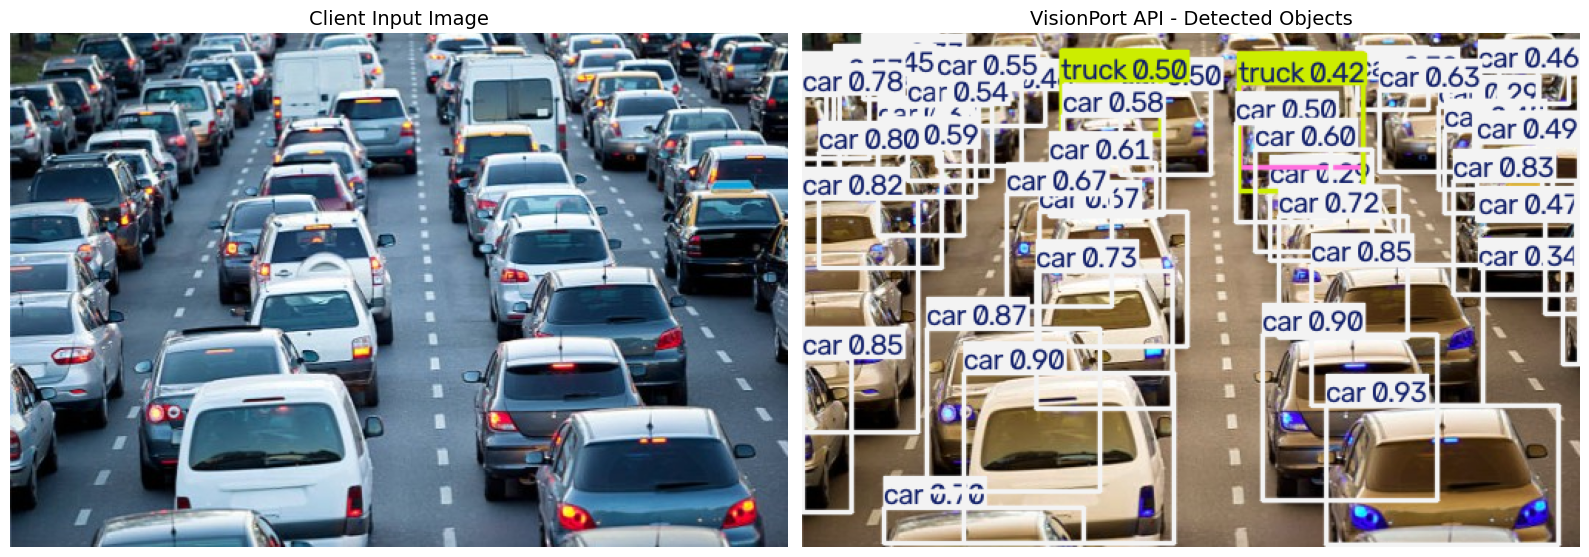

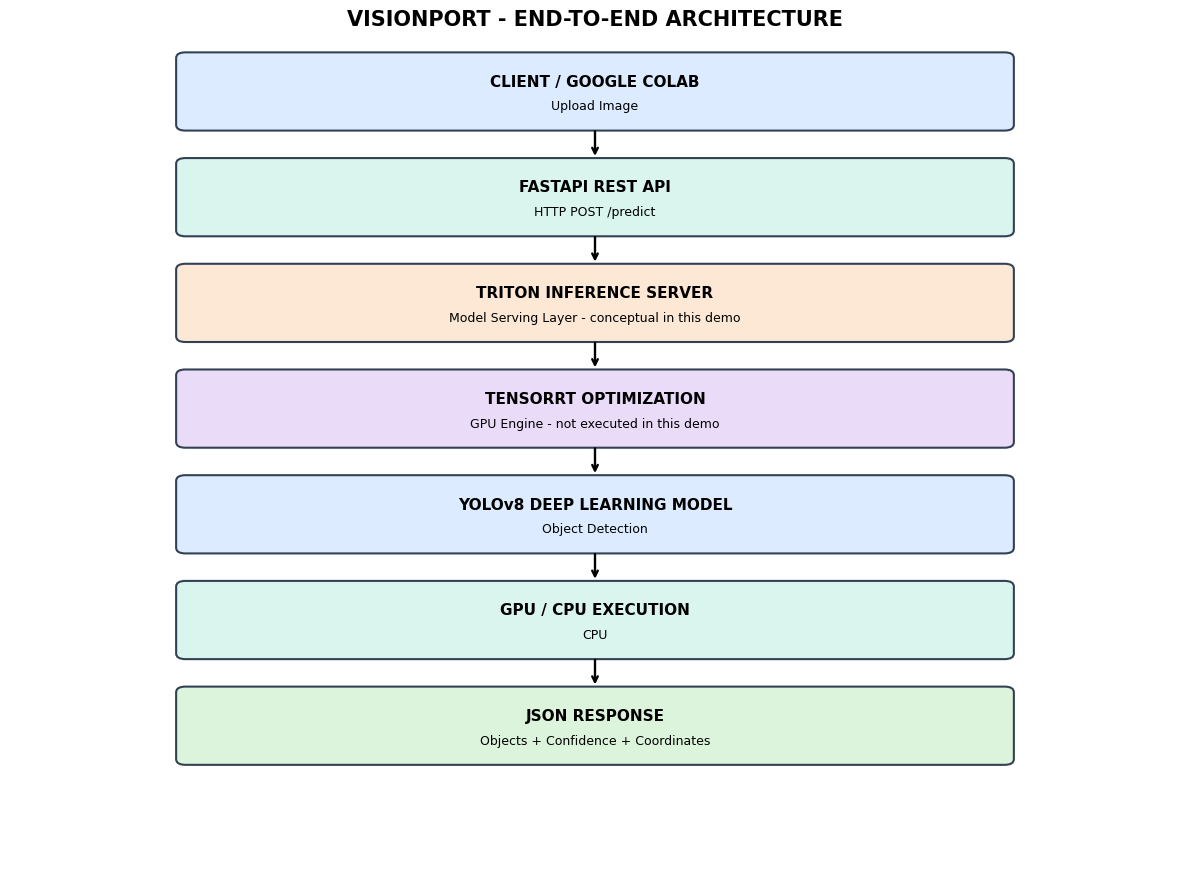

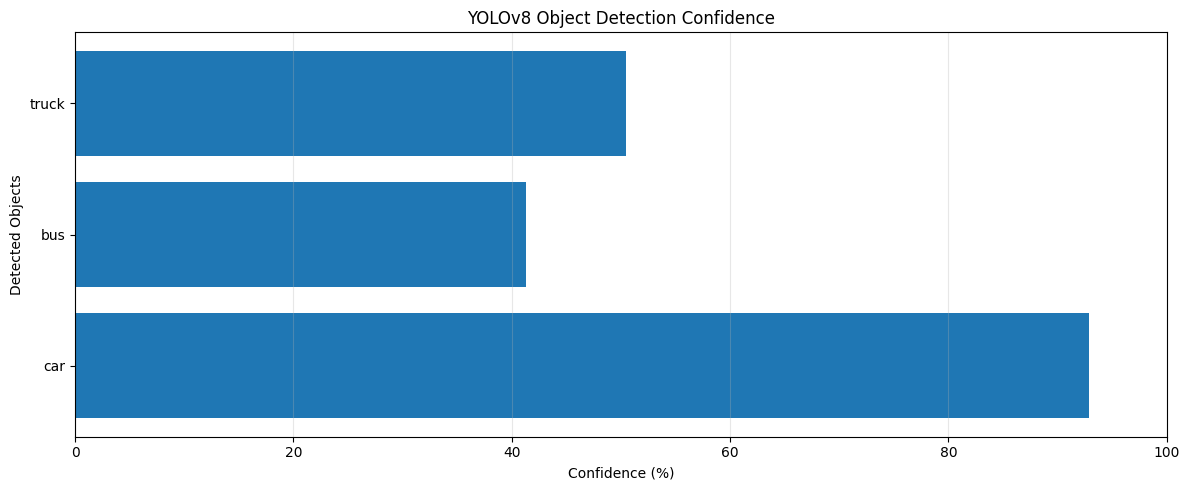

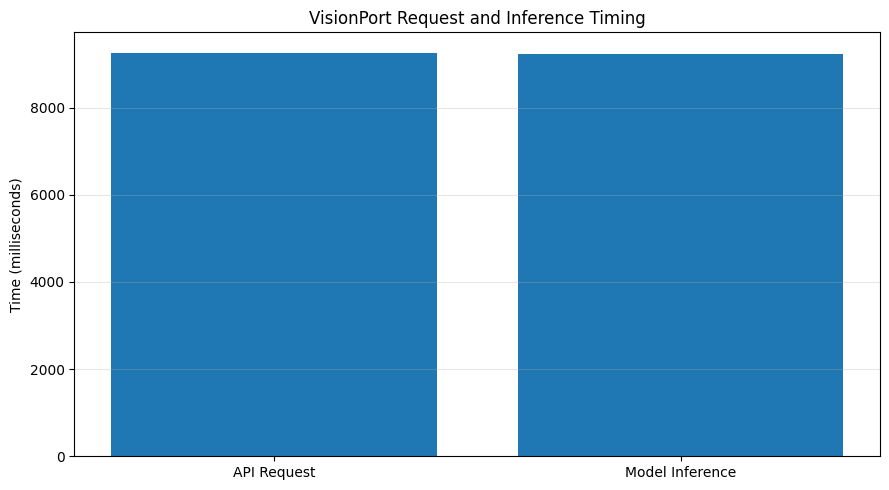


             VISIONPORT FINAL SYSTEM REPORT
Image Acquisition       : SUCCESS
FastAPI Server           : RUNNING
HTTP POST Request        : SUCCESS
YOLOv8 Model             : LOADED
Object Detection         : COMPLETED
Bounding Boxes           : GENERATED
JSON Response            : RECEIVED
GPU Available            : False
TensorRT Available       : False
Triton Client Available  : False
Triton Server Running    : False
Total Objects Detected   : 42
Inference Time           : 9231.42 ms

VISIONPORT END-TO-END PIPELINE COMPLETED!


In [1]:

# ============================================================
# VISIONPORT EXPERIMENT 2
# END-TO-END DEEP LEARNING SYSTEM ARCHITECTURE
# FastAPI + Triton + TensorRT + YOLO + GPU
# ============================================================

# 1. INSTALL DEPENDENCIES
!pip install -q ultralytics fastapi uvicorn python-multipart requests

# 2. IMPORT LIBRARIES
import os
import time
import threading
import requests
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from ultralytics import YOLO
from fastapi import FastAPI, UploadFile, File
from fastapi.responses import JSONResponse
from google.colab import files
from io import BytesIO
from PIL import Image
import uvicorn

print("=" * 65)
print("       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE")
print("=" * 65)

# 3. CHECK HARDWARE AND SOFTWARE
gpu_available = torch.cuda.is_available()

if gpu_available:
    gpu_name = torch.cuda.get_device_name(0)
    hardware = gpu_name
else:
    gpu_name = "No NVIDIA GPU detected"
    hardware = "CPU"

print("\nSYSTEM CONFIGURATION")
print("-" * 45)
print("PyTorch Version:", torch.__version__)
print("GPU Available:", gpu_available)
print("Hardware:", hardware)

# Check TensorRT
try:
    import tensorrt as trt
    tensorrt_available = True
    trt_version = trt.__version__
except Exception:
    tensorrt_available = False
    trt_version = "Not installed"

# Check Triton client availability
try:
    import tritonclient
    triton_client_available = True
except Exception:
    triton_client_available = False

# Check Triton server health endpoint
try:
    triton_response = requests.get(
        "http://localhost:8000/v2/health/ready",
        timeout=2
    )
    triton_running = triton_response.status_code == 200
except Exception:
    triton_running = False

print("TensorRT:", trt_version)
print("Triton Client Installed:", triton_client_available)
print("Triton Server Running:", triton_running)

# 4. UPLOAD IMAGE
print("\nUPLOAD YOUR INPUT IMAGE")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# 5. LOAD YOLO MODEL
print("\nLoading YOLOv8 Model...")
model = YOLO("yolov8n.pt")

print("YOLOv8 Model Loaded Successfully!")

# 6. CREATE FASTAPI APPLICATION
app = FastAPI(
    title="VisionPort Inference API",
    description="End-to-End Deep Learning Image Detection API",
    version="1.0"
)

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLOv8 Nano"
    }

@app.get("/health")
def health():
    return {
        "api_status": "Healthy",
        "model_loaded": True,
        "hardware": hardware
    }

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    start_time = time.time()

    # Read image received through API
    content = await file.read()
    pil_image = Image.open(BytesIO(content)).convert("RGB")
    input_array = np.array(pil_image)

    # Run deep learning inference
    results = model.predict(
        source=input_array,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    inference_time = time.time() - start_time

    # Extract detected objects
    detections = []

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        detections.append({
            "object": model.names[class_id],
            "confidence": round(confidence * 100, 2),
            "box": [round(float(x), 2) for x in box.xyxy[0]]
        })

    return {
        "status": "success",
        "filename": file.filename,
        "total_objects": len(detections),
        "inference_time_ms": round(inference_time * 1000, 2),
        "detections": detections
    }

# 7. START FASTAPI SERVER
def start_server():
    uvicorn.run(
        app,
        host="127.0.0.1",
        port=8000,
        log_level="error"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)
server_thread.start()

# Wait for API server
api_ready = False

for i in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=2
        )
        if response.status_code == 200:
            api_ready = True
            break
    except Exception:
        time.sleep(1)

if not api_ready:
    raise RuntimeError("FastAPI server failed to start!")

print("\nFASTAPI SERVER STARTED SUCCESSFULLY!")
print("API Address: http://127.0.0.1:8000")
print("Health Endpoint: /health")
print("Prediction Endpoint: /predict")

# 8. SEND IMAGE THROUGH FASTAPI
print("\nSending Image Through HTTP POST Request...")

with open(image_path, "rb") as f:
    api_start = time.time()

    api_response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={
            "file": (
                os.path.basename(image_path),
                f,
                "image/jpeg"
            )
        },
        timeout=180
    )

    api_elapsed = time.time() - api_start

if api_response.status_code != 200:
    raise RuntimeError(api_response.text)

output_data = api_response.json()

print("\nAPI RESPONSE RECEIVED!")
print("Status:", output_data["status"])
print("Total Objects:", output_data["total_objects"])
print("Inference Time:", output_data["inference_time_ms"], "ms")

# 9. GET DETECTION IMAGE
original = cv2.imread(image_path)
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

results = model.predict(
    source=original_rgb,
    conf=0.25,
    imgsz=640,
    verbose=False
)

detected_image = results[0].plot()
detected_image = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

# 10. GRAPHICAL OUTPUT - IMAGE DETECTION
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Client Input Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(detected_image)
plt.title("VisionPort API - Detected Objects", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

# 11. GRAPHICAL OUTPUT - ARCHITECTURE
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

architecture = [
    ("CLIENT / GOOGLE COLAB", "Upload Image"),
    ("FASTAPI REST API", "HTTP POST /predict"),
    ("TRITON INFERENCE SERVER",
     "Model Serving Layer - conceptual in this demo"),
    ("TENSORRT OPTIMIZATION",
     "GPU Engine - not executed in this demo"),
    ("YOLOv8 DEEP LEARNING MODEL", "Object Detection"),
    ("GPU / CPU EXECUTION", hardware),
    ("JSON RESPONSE", "Objects + Confidence + Coordinates")
]

colors = [
    "#DCEBFF", "#D9F5EE", "#FCE8D5",
    "#EADCF8", "#DCEBFF", "#D9F5EE", "#DDF4DC"
]

for i, (title, subtitle) in enumerate(architecture):
    y = 10.7 - i * 1.5

    rect = patches.FancyBboxPatch(
        (1.5, y), 7, 0.95,
        boxstyle="round,pad=0.08",
        facecolor=colors[i],
        edgecolor="#334155",
        linewidth=1.5
    )

    ax.add_patch(rect)

    ax.text(
        5, y + 0.62, title,
        ha="center", va="center",
        fontsize=11, fontweight="bold"
    )

    ax.text(
        5, y + 0.27, subtitle,
        ha="center", va="center",
        fontsize=9
    )

    if i < len(architecture) - 1:
        ax.annotate(
            "", xy=(5, y - 0.48),
            xytext=(5, y - 0.05),
            arrowprops=dict(arrowstyle="->", lw=1.7)
        )

plt.title(
    "VISIONPORT - END-TO-END ARCHITECTURE",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# 12. GRAPHICAL OUTPUT - OBJECT CONFIDENCE
detections = output_data["detections"]

if detections:
    object_names = [d["object"] for d in detections]
    confidence = [d["confidence"] for d in detections]

    plt.figure(figsize=(12, 5))

    plt.barh(
        object_names[::-1],
        confidence[::-1]
    )

    plt.xlabel("Confidence (%)")
    plt.ylabel("Detected Objects")
    plt.title("YOLOv8 Object Detection Confidence")
    plt.xlim(0, 100)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

# 13. GRAPHICAL OUTPUT - SYSTEM METRICS
metrics = {
    "API Request": api_elapsed * 1000,
    "Model Inference": output_data["inference_time_ms"]
}

plt.figure(figsize=(9, 5))
plt.bar(
    metrics.keys(),
    metrics.values()
)
plt.ylabel("Time (milliseconds)")
plt.title("VisionPort Request and Inference Timing")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 14. FINAL SYSTEM REPORT
print("\n" + "=" * 65)
print("             VISIONPORT FINAL SYSTEM REPORT")
print("=" * 65)

print("Image Acquisition       : SUCCESS")
print("FastAPI Server           : RUNNING")
print("HTTP POST Request        : SUCCESS")
print("YOLOv8 Model             : LOADED")
print("Object Detection         : COMPLETED")
print("Bounding Boxes           : GENERATED")
print("JSON Response            : RECEIVED")
print("GPU Available            :", gpu_available)
print("TensorRT Available       :", tensorrt_available)
print("Triton Client Available  :", triton_client_available)
print("Triton Server Running    :", triton_running)
print("Total Objects Detected   :", len(detections))
print("Inference Time           :",
      output_data["inference_time_ms"], "ms")
print("=" * 65)

print("\nVISIONPORT END-TO-END PIPELINE COMPLETED!")
